# <a id='toc1_'></a>[FashionCLIP](#toc0_)

**Table of contents**<a id='toc0_'></a>    
- [FashionCLIP](#toc1_)    
  - [Datos y etiquetas](#toc1_1_)    
  - [Embeddings de FashionCLIP](#toc1_2_)    
  - [Zero-shot](#toc1_3_)    
  - [Linear probe](#toc1_4_)    
  - [Comparación con el multitarea v2](#toc1_5_)    
  - [Resumen](#toc1_6_)    

<!-- vscode-jupyter-toc-config
	numbering=false
	anchor=true
	flat=false
	minLevel=1
	maxLevel=6
	/vscode-jupyter-toc-config -->
<!-- THIS CELL WILL BE REPLACED ON TOC UPDATE. DO NOT WRITE YOUR TEXT IN THIS CELL -->

> En este notebook comparamos nuestro modelo multitarea v2 con **FashionCLIP**, un modelo de imagen y texto ya entrenado con productos de moda. No lo reentrenamos: lo usamos tal cual para ver si un modelo preentrenado específico de moda mejora lo que hemos conseguido con la ResNet18.

**Objetivos:**
1. Calcular los embeddings de FashionCLIP de todas las imágenes del catálogo.
2. Clasificar sin entrenar nada (*zero-shot*), comparando cada imagen con frases como "a photo of shirts".
3. Entrenar solo una regresión logística sobre los embeddings congelados (*linear probe*).
4. Comparar los dos enfoques con el multitarea v2 en test, con las mismas clases y el mismo split.

FashionCLIP es CLIP (un modelo que aprende a relacionar imágenes y textos) ajustado con unas 700.000 parejas de imagen y descripción de productos de moda. Es de código abierto (licencia MIT) y se ejecuta en local.

Lo usamos de dos formas:
- **Zero-shot**: escribimos una frase por clase y asignamos a cada imagen la frase más parecida. No necesita entrenamiento, pero no puede predecir `Other`, porque no es una clase con significado.
- **Linear probe**: congelamos FashionCLIP y entrenamos solo una regresión logística por tarea sobre sus embeddings, con el mismo train que el v2.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mlflow
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

plt.style.use('seaborn-v0_8-whitegrid')

from fashion_mlops.config import PROCESSED_DATA_DIR, IMAGES_DIR, MULTITASK_MODEL_NAME
from fashion_mlops.data.make_dataset import add_multitask_labels
from fashion_mlops.data.dataset import make_loaders
from fashion_mlops.models.train import get_device, compute_metrics
from fashion_mlops.models.multitask import predict_multitask
from fashion_mlops.models.tracking import setup_mlflow
from fashion_mlops.models.fashionclip import (
    FASHIONCLIP_MODEL_ID, load_fashionclip, compute_clip_image_embeddings, compute_clip_text_embeddings,
    zero_shot_predict,
)

## <a id='toc1_1_'></a>[Datos y etiquetas](#toc0_)

Usamos exactamente las mismas clases que el multitarea v2 (versión 2 de `fashion-multitask`), leyendo sus mapeos desde MLflow, para que la comparación sea justa.

In [2]:
V2_VERSION = 2
CLIP_EMBEDDINGS_PATH = PROCESSED_DATA_DIR / "embeddings_fashionclip.npz"

device = get_device()
setup_mlflow(experiment_name="fashionclip")
client = mlflow.MlflowClient()

v2_version = client.get_model_version(MULTITASK_MODEL_NAME, V2_VERSION)
v2_params = client.get_run(v2_version.run_id).data.params
label_mappings = mlflow.artifacts.load_dict(f"runs:/{v2_version.run_id}/label_mappings.json")
TASKS = list(label_mappings)
classes = {task: sorted(mapping, key=mapping.get) for task, mapping in label_mappings.items()}

df = add_multitask_labels(
    pd.read_csv(PROCESSED_DATA_DIR / "styles_splits.csv"),
    label_mappings=label_mappings, min_count=int(v2_params["min_train_examples"]),
)
splits = {split: (df["split"] == split).to_numpy() for split in ["train", "val", "test"]}
y = {task: df[f"{task}_idx_mt"].to_numpy() for task in TASKS}

print(f"Dispositivo: {device} | tareas: {TASKS}")
pd.Series({task: len(classes[task]) for task in TASKS}, name="n_clases")

Dispositivo: mps | tareas: ['masterCategory', 'subCategory', 'articleType', 'baseColour', 'gender']


masterCategory     5
subCategory       23
articleType       50
baseColour        28
gender             5
Name: n_clases, dtype: int64

## <a id='toc1_2_'></a>[Embeddings de FashionCLIP](#toc0_)

Calculamos una vez el embedding de 512 dimensiones de cada imagen y lo guardamos, porque lo usan los dos enfoques.

In [3]:
clip_model, clip_processor = load_fashionclip(device)

if CLIP_EMBEDDINGS_PATH.exists():
    data = np.load(CLIP_EMBEDDINGS_PATH)
    assert (data["ids"] == df["id"].to_numpy()).all()
    clip_embeddings = data["embeddings"]
else:
    clip_embeddings = compute_clip_image_embeddings(clip_model, clip_processor, df, IMAGES_DIR, device)
    np.savez(CLIP_EMBEDDINGS_PATH, ids=df["id"].to_numpy(), embeddings=clip_embeddings)

clip_embeddings.shape

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

(44414, 512)

## <a id='toc1_3_'></a>[Zero-shot](#toc0_)

Una frase en inglés por clase (el modelo se entrenó con descripciones en inglés). Evaluamos en test **sin las imágenes de `Other`**, porque zero-shot no puede predecir esa clase.

In [4]:
PROMPTS = {
    "masterCategory": "a photo of {}",
    "subCategory": "a photo of {}",
    "articleType": "a photo of {}",
    "baseColour": "a photo of a {} fashion product",
    "gender": "a photo of a fashion product for {}",
}


def known_metrics(y_true, y_pred):
    """
    Accuracy y F1-macro solo sobre las clases reales presentes (sin Other), para comparar
    modelos que sí pueden predecir Other con zero-shot, que no puede.
    """
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "f1_macro": f1_score(y_true, y_pred, labels=np.unique(y_true), average="macro", zero_division=0),
    }


# Imágenes de test cuya clase real no es Other, por tarea
test_known = {task: splits["test"] & (df[f"{task}_mt"] != "Other").to_numpy() for task in TASKS}

zs_metrics = {}
for task in TASKS:
    candidates = [c for c in classes[task] if c != "Other"]
    text_embeddings = compute_clip_text_embeddings(
        clip_model, clip_processor, [PROMPTS[task].format(c.lower()) for c in candidates], device
    )
    pred = zero_shot_predict(clip_embeddings[test_known[task]], text_embeddings)
    pred = np.array([label_mappings[task][candidates[i]] for i in pred])
    zs_metrics[task] = known_metrics(y[task][test_known[task]], pred)

with mlflow.start_run(run_name="fashionclip_zero_shot"):
    mlflow.log_params({
        "model_id": FASHIONCLIP_MODEL_ID, "method": "zero_shot", "tasks": ",".join(TASKS),
        **{f"prompt_{task}": prompt for task, prompt in PROMPTS.items()},
    })
    mlflow.log_metrics({f"test_known_{task}_{k}": v for task, m in zs_metrics.items() for k, v in m.items()})

pd.DataFrame(zs_metrics).T.round(4)

,accuracy,f1_macro
masterCategory,0.9295,0.8643
subCategory,0.6523,0.7243
articleType,0.7557,0.6767
baseColour,0.5808,0.4185
gender,0.7078,0.4645


## <a id='toc1_4_'></a>[Linear probe](#toc0_)

Una regresión logística por tarea sobre los embeddings congelados. Elegimos la regularización `C` con el F1-macro en validación y evaluamos una sola vez en test.

In [5]:
PROBE_C = [0.01, 0.1, 1.0]

probe_val, probe_test, probe_pred, probe_best_c = {}, {}, {}, {}
X = {split: clip_embeddings[mask] for split, mask in splits.items()}

for task in TASKS:
    y_split = {split: y[task][mask] for split, mask in splits.items()}

    # Una regresión por valor de C, nos quedamos con la mejor en validación
    candidates = {}
    for c in PROBE_C:
        clf = make_pipeline(StandardScaler(), LogisticRegression(C=c, max_iter=2000))
        clf.fit(X["train"], y_split["train"])
        candidates[c] = (clf, compute_metrics(y_split["val"], clf.predict(X["val"])))

    probe_best_c[task] = max(candidates, key=lambda c: candidates[c][1]["f1_macro"])
    best_clf, probe_val[task] = candidates[probe_best_c[task]]
    probe_pred[task] = best_clf.predict(X["test"])
    probe_test[task] = compute_metrics(y_split["test"], probe_pred[task])
    print(f"{task}: C={probe_best_c[task]} | val F1-macro {probe_val[task]['f1_macro']:.4f} | test F1-macro {probe_test[task]['f1_macro']:.4f}")

with mlflow.start_run(run_name="fashionclip_linear_probe"):
    mlflow.log_params({
        "model_id": FASHIONCLIP_MODEL_ID, "method": "linear_probe", "tasks": ",".join(TASKS),
        "classifier": "logistic_regression", "c_grid": str(PROBE_C),
        **{f"best_c_{task}": c for task, c in probe_best_c.items()},
    })
    mlflow.log_metrics({f"val_{task}_{k}": v for task, m in probe_val.items() for k, v in m.items()})
    mlflow.log_metrics({f"test_{task}_{k}": v for task, m in probe_test.items() for k, v in m.items()})

pd.DataFrame(probe_test).T.round(4)

masterCategory: C=1.0 | val F1-macro 0.8288 | test F1-macro 0.8297
subCategory: C=0.01 | val F1-macro 0.9367 | test F1-macro 0.9381
articleType: C=0.1 | val F1-macro 0.8713 | test F1-macro 0.8616
baseColour: C=0.01 | val F1-macro 0.5414 | test F1-macro 0.5312
gender: C=0.01 | val F1-macro 0.7970 | test F1-macro 0.7916


,accuracy,balanced_accuracy,f1_macro
masterCategory,0.9926,0.8262,0.8297
subCategory,0.9691,0.9391,0.9381
articleType,0.8908,0.8625,0.8616
baseColour,0.7116,0.5100,0.5312
gender,0.9228,0.7636,0.7916


## <a id='toc1_5_'></a>[Comparación con el multitarea v2](#toc0_)

Calculamos las predicciones del v2 en test para comparar las tres opciones con las mismas imágenes.

In [6]:
v2_model = mlflow.pytorch.load_model(f"models:/{MULTITASK_MODEL_NAME}/{V2_VERSION}", map_location=device)
test_loader = make_loaders(df, IMAGES_DIR, label_col=[f"{task}_idx_mt" for task in TASKS])["test"]
v2_true, v2_pred = predict_multitask(v2_model, test_loader, device, TASKS)

# El loader de test mantiene el orden del DataFrame
assert all((v2_true[task] == y[task][splits["test"]]).all() for task in TASKS)

comparison = pd.DataFrame({
    "multitarea v2": {task: compute_metrics(v2_true[task], v2_pred[task])["f1_macro"] for task in TASKS},
    "FashionCLIP linear probe": {task: probe_test[task]["f1_macro"] for task in TASKS},
})
comparison.round(4)

,multitarea v2,FashionCLIP linear probe
masterCategory,0.8694,0.8297
subCategory,0.9377,0.9381
articleType,0.8348,0.8616
baseColour,0.5016,0.5312
gender,0.7795,0.7916


Sin las imágenes de `Other` podemos añadir también el zero-shot:

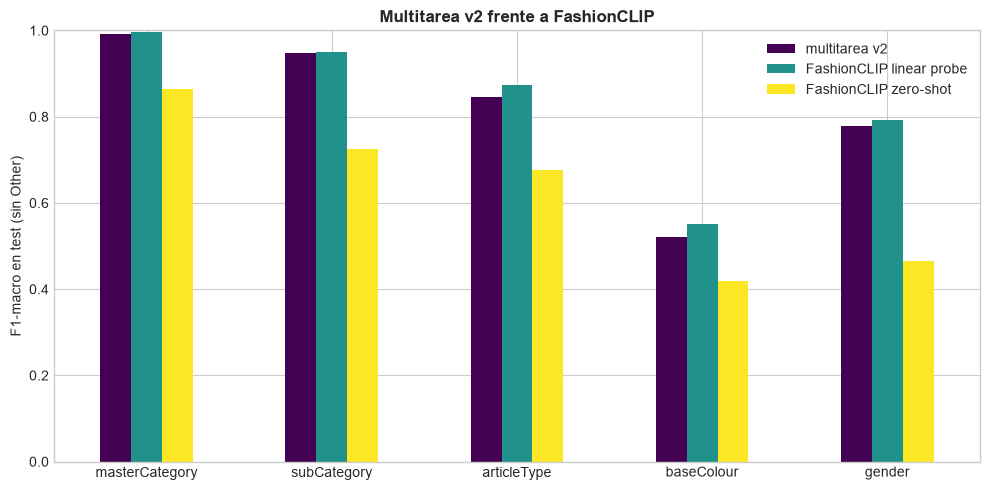

,multitarea v2,FashionCLIP linear probe,FashionCLIP zero-shot
masterCategory,0.9916,0.9954,0.8643
subCategory,0.9475,0.9493,0.7243
articleType,0.8456,0.8740,0.6767
baseColour,0.5200,0.5518,0.4185
gender,0.7795,0.7916,0.4645


In [8]:
known_comparison = {}
for task in TASKS:
    known = test_known[task][splits["test"]]
    known_comparison[task] = {
        "multitarea v2": known_metrics(v2_true[task][known], v2_pred[task][known])["f1_macro"],
        "FashionCLIP linear probe": known_metrics(v2_true[task][known], probe_pred[task][known])["f1_macro"],
        "FashionCLIP zero-shot": zs_metrics[task]["f1_macro"],
    }

known_comparison = pd.DataFrame(known_comparison).T

fig, ax = plt.subplots(figsize=(10, 5))
known_comparison.plot(kind="bar", ax=ax, rot=0, colormap="viridis")
ax.set_ylim(0, 1)
ax.set_ylabel("F1-macro en test (sin Other)")
ax.set_title("Multitarea v2 frente a FashionCLIP", fontweight="bold")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

known_comparison.round(4)

**Zero-shot.** Sin entrenar nada acierta bien la categoría (F1-macro 0,864 sin `Other`), pero se queda lejos en el resto: subcategoría 0,72, tipo 0,68, color 0,42 y género 0,46. Depende mucho de las frases, y los nombres de clase del dataset (`Topwear`, `Bottomwear`, `Unisex`...) no se parecen a cómo se describe un producto en un texto.

**Linear probe.** Con solo una regresión logística sobre los embeddings congelados, FashionCLIP **iguala o supera al v2** en test en cuatro de las cinco tareas:
- **Tipo de artículo**: 0,862 frente a 0,835.
- **Color**: 0,531 frente a 0,502 (accuracy 0,712 frente a 0,666).
- **Género**: 0,792 frente a 0,780.
- **Subcategoría**: 0,938, igual.
- **Categoría**: 0,830 frente a 0,869, pero la diferencia viene de `Other`: sin esa clase quedan prácticamente igual (0,995 y 0,992).

Vemos dos motivos:
- FashionCLIP se preentrenó con unos 700.000 productos de moda y sus descripciones, que hablan del tipo, el color o el género. Nuestra ResNet18 partía de ImageNet y la ajustamos con 31.000 imágenes.
- Cada tarea tiene su propio clasificador sobre un embedding fijo, así que el color no compite con el tipo por la misma red, como pasaba en el v2.

A cambio, la parte de imagen de FashionCLIP es unas **8 veces más grande** (88 M de parámetros frente a 11 M), recorta las imágenes a un cuadrado, y las diferencias son pequeñas y de una sola ejecución.

Para la app seguimos con el v2, que ya está registrado en MLflow y desplegado. Usar FashionCLIP como base de la app (sus embeddings para buscar parecidos y un clasificador lineal por tarea) queda como mejora futura.

## <a id='toc1_6_'></a>[Resumen](#toc0_)

- Hemos comparado nuestro multitarea v2 con **FashionCLIP** congelado, con las mismas clases y el mismo split, sin reentrenarlo.
- **Zero-shot** (sin entrenar nada): bueno en la categoría (0,864 sin `Other`), pero muy por debajo del v2 en el resto de tareas.
- **Linear probe** (una regresión logística por tarea): iguala o supera al v2 en tipo de artículo (0,862 frente a 0,835), color (0,531 frente a 0,502), género (0,792 frente a 0,780) y subcategoría (0,938). En la categoría queda por debajo solo por `Other`.
- Un modelo preentrenado específicamente en moda da mejores características que ImageNet + fine-tuning con nuestros datos, a cambio de un modelo unas 8 veces más grande.
- Los dos runs quedan registrados en el experimento `fashionclip` de MLflow. La app sigue con el v2, y usar FashionCLIP en la app queda como mejora futura.